In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy
import sklearn

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

print("All libraries imported successfully!")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Statsmodels:", sm.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NumPy: 2.4.6
Pandas: 3.1.0
Statsmodels: 0.15.0
Scikit-learn: 1.5.2


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
df = pd.read_csv(r"C:\Users\user\Downloads\archive (13)\Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())


   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                         

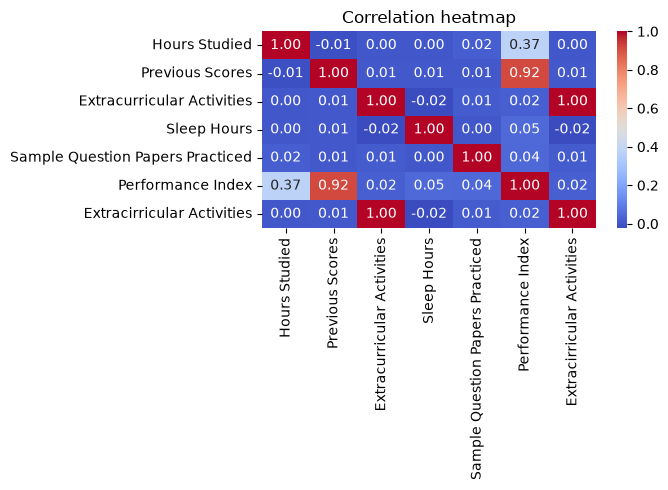

In [4]:
df["Extracurricular Activities"]=df["Extracirricular Activities"] =df["Extracurricular Activities"].map({"Yes":1,"No":0})
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

In [6]:
X_simple = df[["Hours Studied"]]
y = df ["Performance Index"]

xs_train, Xs_test, ys_train, ys_test = train_test_split(
X_simple, y, test_size=0.2, random_state=42)

simple_model = LinearRegression()
simple_model.fit(xs_train , ys_train)
print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0): ", simple_model.intercept_)
print("Slope (b1)    : ", simple_model.coef_[0])

ys_pred = simple_model.predict(Xs_test)
print("R2     : ", r2_score(ys_test, ys_pred))
print("RMSE   : ", np.sqrt(mean_squared_error(ys_test, ys_pred)))


=== SIMPLE LINEAR REGRESSION ===
Intercept (b0):  41.43663482653601
Slope (b1)    :  2.7843004411707217
R2     :  0.13160425385996788
RMSE   :  17.93919001285204


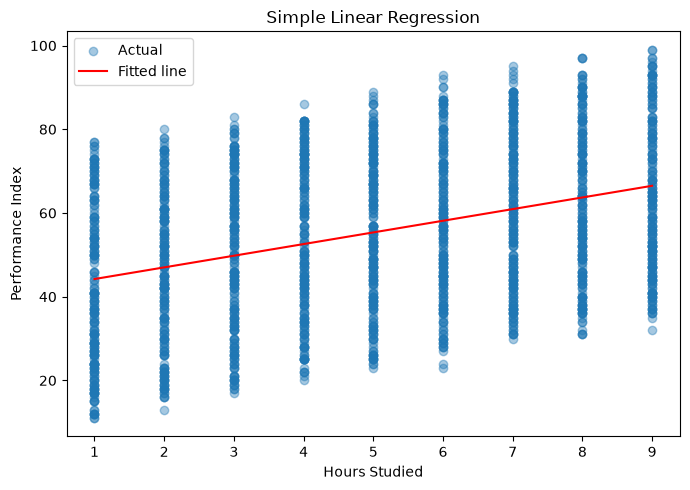

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(Xs_test.sort_values("Hours Studied"),
         simple_model.predict(Xs_test.sort_values("Hours Studied")),
         color="red", label="Fitted line")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

In [14]:
X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept: ", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"  {name:35s} {coef: .4f}")

y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print("R2           :", r2)
print("Adjusted R2  :", adj_r2)
print("RMSE         :", rmse)


=== MULTIPLE LINEAR REGRESSION ===
Intercept:  -33.92194621555607
  Hours Studied                        2.8525
  Previous Scores                      1.0170
  Extracurricular Activities           0.3043
  Sleep Hours                          0.4769
  Sample Question Papers Practiced     0.1918
  Extracirricular Activities           0.3043
R2           : 0.9889832909573145
Adjusted R2  : 0.9889501247484555
RMSE         : 2.0205515085050063


C:\Users\user\AppData\Local\Temp\ipykernel_12756\1659305475.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols = sm.OLS(y_train, X_train_sm).fit()



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:48:19   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

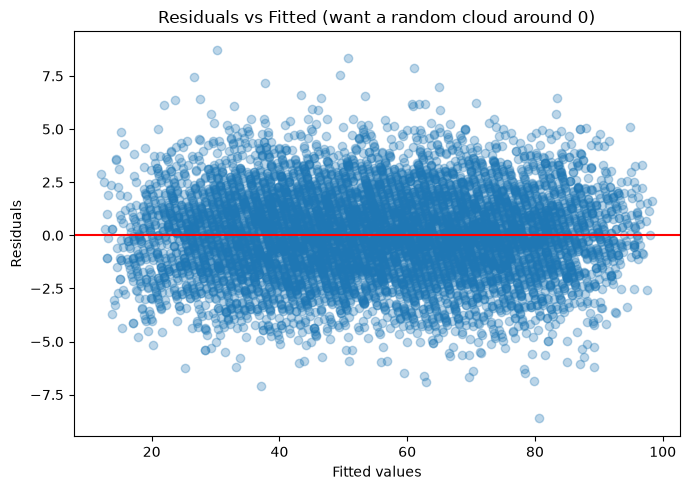

In [15]:
X_train_sm = sm.add_constant(X_train)       
ols = sm.OLS(y_train, X_train_sm).fit()    
print("\n", ols.summary())

fitted = ols.fittedvalues
resid = ols.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (want a random cloud around 0)")
plt.tight_layout()

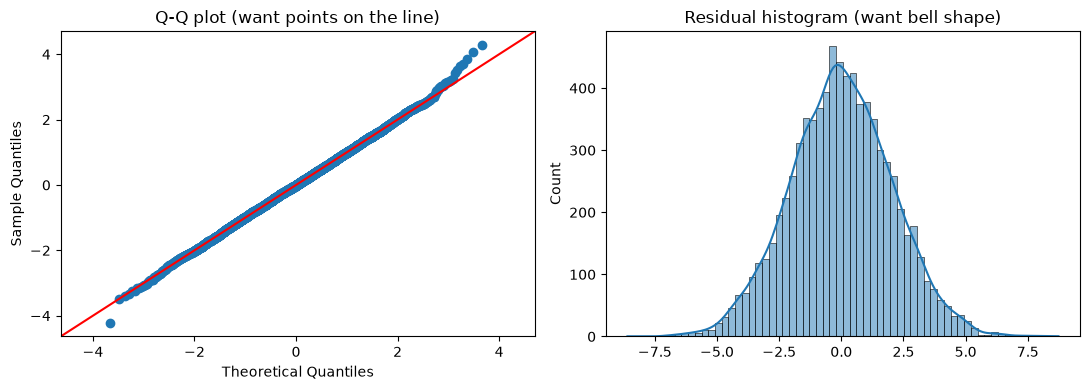

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

In [17]:
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

Breusch-Pagan p-value: 0.3442422995675376


C:\Users\user\anaconda3\Lib\site-packages\statsmodels\stats\diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


In [18]:
print("Durbin-Watson:", durbin_watson(resid))

Durbin-Watson: 2.033106022504012


In [19]:
vif = pd.DataFrame({
    "Feature": X_train_sm.columns,
    "VIF": [variance_inflation_factor(X_train_sm.values, i)
            for i in range(X_train_sm.shape[1])]
})

print("\nVIF:\n", vif[vif["Feature"] != "const"])


VIF:
                             Feature           VIF
1                     Hours Studied  1.000387e+00
2                   Previous Scores  1.000176e+00
3        Extracurricular Activities  1.000800e+15
4                       Sleep Hours  1.000461e+00
5  Sample Question Papers Practiced  1.000320e+00
6        Extracirricular Activities  1.000800e+15


C:\Users\user\AppData\Local\Temp\ipykernel_12756\2565631041.py:3: UserWarning: The design matrix is poorly conditioned (condition number=1.61e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(X_train_sm.values, i)
C:\Users\user\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\user\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\user\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\user\anaconda3\Lib\site-p

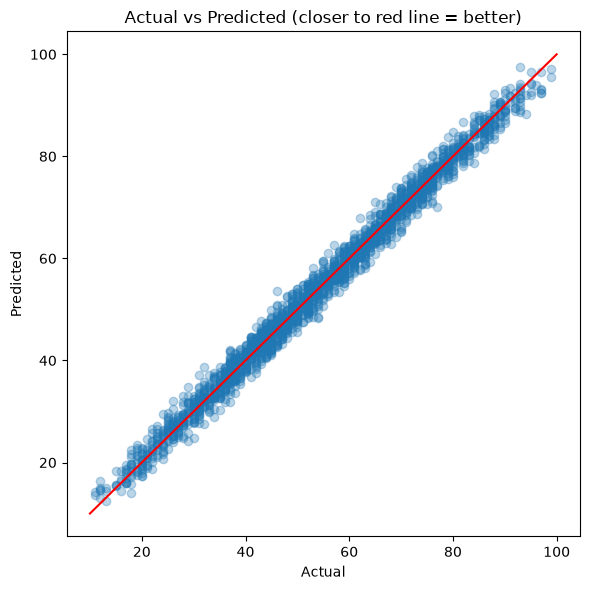

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")  # perfect-predict
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()